## 1. 环境与 Python 基础

In [20]:
import sys
import numpy as np
import pandas as pd
from IPython.display import display
print(sys.version)
print('NumPy:', np.__version__, 'Pandas:', pd.__version__)

def fahrenheit(c):
    return c * 9 / 5 + 32
tem = float(input("温度："))
print(tem,'对应华氏温度：', fahrenheit(tem))

score = float(input("分数："))
print('等级：', 'A' if score >= 90 else 'B' if score >= 80 else'C' if score >= 70 else 'D' if score >= 60 else 'F')

sales = [120, 880, 9980, 45, 320, 760]
mean, count = sum(sales) / len(sales), 0
for x in sales:
    if x > mean:
        count += 1
print('平均值：', mean, '超过均值的个数：', count)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy: 2.4.6 Pandas: 3.0.5
88.0 对应华氏温度： 190.4
等级： A
平均值： 2017.5 超过均值的个数： 1


## 2. NumPy

In [21]:
a = np.random.default_rng(42).integers(0, 101, (5, 5))
print('原矩阵：\n',a)
print('形状、类型：\n', a.shape, a.dtype)
print('最大、最小、均值、标准差：\n', a.max(), a.min(), a.mean(), a.std())
print('转置：\n', a.T)
print('一维数组：\n', a.reshape(-1))
print('每行均值：\n', a.mean(axis=1))

原矩阵：
 [[ 9 78 66 44 43]
 [86  8 70 20  9]
 [53 98 74 76 72]
 [79 51 12 84 45]
 [50 37 18 93 78]]
形状、类型：
 (5, 5) int64
最大、最小、均值、标准差：
 98 8 54.12 28.117354071818355
转置：
 [[ 9 86 53 79 50]
 [78  8 98 51 37]
 [66 70 74 12 18]
 [44 20 76 84 93]
 [43  9 72 45 78]]
一维数组：
 [ 9 78 66 44 43 86  8 70 20  9 53 98 74 76 72 79 51 12 84 45 50 37 18 93
 78]
每行均值：
 [48.  38.6 74.6 54.2 55.2]


## 3. Pandas
### 读取、概览与去重

In [22]:
df = pd.read_csv('实验一_销售流水_原始.csv')
print('原始形状：', df.shape)
df.info()
display(df.head())
print('重复行数：', df.duplicated().sum())
df = df.drop_duplicates().copy()

原始形状： (1012, 6)
<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    1012 non-null   str    
 1   order_time  1012 non-null   str    
 2   store       1002 non-null   str    
 3   category    997 non-null    str    
 4   amount      987 non-null    str    
 5   quantity    991 non-null    float64
dtypes: float64(1), str(5)
memory usage: 47.6 KB


,order_id,order_time,store,category,amount,quantity
0,D260301001,03-01-2026 09:42,B店,服饰,664.13,3.0
1,D260301002,2026-03-01 11:18:00,A店,服饰,320元,2.0
2,D260301003,2026/3/1 11:23,A店,家电,¥630.14,1.0
3,D260301004,2026-03-01 12:04:00,B店,家电,196元,2.0
4,D260301005,2026/3/1 15:28,A店,食品,574元,1.0


重复行数： 12


### 类型转换与标签统一
金额去除货币符号，统一门店和类别。混合日期按实验给出的美式月-日-年解释。

In [23]:
df['amount'] = pd.to_numeric(df['amount'].str.replace(r'[¥￥元,，\s]', '', regex=True))
df['quantity'] = pd.to_numeric(df['quantity'])
df['store'] = df['store'].str.strip().str.upper().str.replace('门店', '店')
df['category'] = df['category'].str.strip().str.replace('类', '')
df['order_time'] = pd.to_datetime(df['order_time'], format='mixed', dayfirst=False)
display(df.head())

,order_id,order_time,store,category,amount,quantity
0,D260301001,2026-03-01 09:42:00,B店,服饰,664.13,3.0
1,D260301002,2026-03-01 11:18:00,A店,服饰,320.00,2.0
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1.0
3,D260301004,2026-03-01 12:04:00,B店,家电,196.00,2.0
4,D260301005,2026-03-01 15:28:00,A店,食品,574.00,1.0


### 筛选
本步展示清洗前查询；最终月销量在清洗后重新统计。

In [24]:
display(df.groupby(df['order_time'].dt.to_period('M'))['quantity'].sum().rename('清洗前月销量'))
display(df.query('amount > 1000'))
display(df.query("store == 'A店' and category == '家电'").head())

order_time
2026-03    920.0
2026-04    815.0
2026-05    963.0
2026-06     70.0
Freq: M, Name: 清洗前月销量, dtype: float64

,order_id,order_time,store,category,amount,quantity
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.0,2.0
601,D260426005,2026-04-26 15:47:00,B店,图书,88888.0,3.0
770,D260512008,2026-05-12 16:59:00,A店,家电,77777.0,1.0


,order_id,order_time,store,category,amount,quantity
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1.0
19,D260302009,2026-03-02 21:05:00,A店,家电,629.06,3.0
22,D260303002,2026-03-03 09:23:00,A店,家电,400.96,5.0
25,D260303005,2026-03-03 14:10:00,A店,家电,324.51,1.0
29,D260304001,2026-03-04 09:10:00,A店,家电,725.28,1.0


### 缺失与异常处理
 - 先展示缺失及异常。IQR 仅标记候选；
 - 实验说明已明确三个极值为异常，本次剔除这些订单、负金额及非正数量。
 - 随后用有效样本中位数填数值缺失，分类缺失填“未知”。
 - 先排除异常再计算中位数，避免污染填充值。真实业务中的负金额还需核对是否为退款。

In [25]:
display(df.isna().sum().rename('处理前缺失数量'))
q1, q3 = df['amount'].quantile([0.25, 0.75])
iqr = q3 - q1
display(df[df['amount'].lt(q1 - 1.5 * iqr) | df['amount'].gt(q3 + 1.5 * iqr)])
bad = (df['amount'] < 0) | df['amount'].isin([999999, 88888, 77777]) | (df['quantity'] <= 0)
display(df[bad])
df = df[~bad].copy()
df = df.fillna({'amount': df['amount'].median(), 'quantity': df['quantity'].median(),
                'store': '未知', 'category': '未知'})
df['quantity'] = df['quantity'].astype(int)
print('清洗后形状：', df.shape)
display(df.isna().sum().rename('处理后缺失数量'))

order_id       0
order_time     0
store         10
category      15
amount        25
quantity      20
Name: 处理前缺失数量, dtype: int64

,order_id,order_time,store,category,amount,quantity
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.0,2.0
601,D260426005,2026-04-26 15:47:00,B店,图书,88888.0,3.0
770,D260512008,2026-05-12 16:59:00,A店,家电,77777.0,1.0


,order_id,order_time,store,category,amount,quantity
34,D260304006,2026-03-04 13:35:00,A店,服饰,-260.00,2.0
78,D260308003,2026-03-08 11:47:00,A店,食品,-260.00,3.0
116,D260311010,2026-03-11 20:47:00,A店,食品,101.00,-1.0
133,D260313008,2026-03-13 14:49:00,C店,图书,-80.00,1.0
222,D260321006,2026-03-21 18:38:00,B店,家电,-199.00,4.0
284,D260327011,2026-03-27 20:33:00,C店,家电,-50.00,3.0
401,D260407006,2026-04-07 11:24:00,C店,家电,672.89,0.0
415,D260408009,2026-04-08 14:47:00,A店,食品,83.00,0.0
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.00,2.0
488,D260415008,2026-04-15 18:17:00,B店,图书,-199.00,4.0


清洗后形状： (981, 6)


order_id      0
order_time    0
store         0
category      0
amount        0
quantity      0
Name: 处理后缺失数量, dtype: int64

### 聚合、透视与保存
销量是数量之和，订单笔数是记录数；金额按订单直接求和。CSV 保存于 Notebook 同目录。

In [26]:
display(df.groupby(df['order_time'].dt.to_period('M'))['quantity'].sum().rename('最终月销量'))
display(df.groupby('store').agg(销售额=('amount', 'sum'), 平均订单额=('amount', 'mean'),
                              订单笔数=('order_id', 'count')).round(2))
display(df.pivot_table(index='store', columns='category', values='amount',
                       aggfunc='sum', fill_value=0, margins=True).round(2))
df.to_csv('实验一_精简版_清洗结果.csv', index=False, encoding='utf-8-sig')

order_time
2026-03    920
2026-04    825
2026-05    959
2026-06     74
Freq: M, Name: 最终月销量, dtype: int64

,销售额,平均订单额,订单笔数
store,,,
A店,146419.75,400.05,366
B店,138766.20,419.23,331
C店,109637.99,400.14,274
未知,3240.68,324.07,10


category,图书,家电,服饰,未知,食品,All
store,,,,,,
A店,22607.25,69475.33,30659.85,1844.59,21832.73,146419.75
B店,54944.66,23227.66,28112.54,2322.26,30159.08,138766.20
C店,22193.92,35565.75,26139.37,1542.24,24196.71,109637.99
未知,1071.61,986.12,932.18,0.00,250.77,3240.68
All,100817.44,129254.86,85843.94,5709.09,76439.29,398064.62


## 4. Matplotlib 选做：各门店销售额柱状图

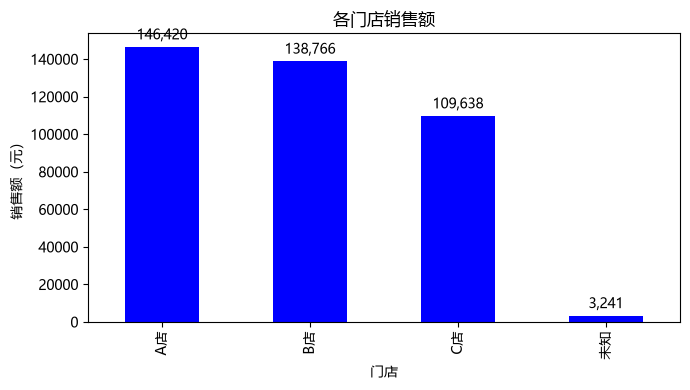

In [27]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
summary = df.groupby('store')['amount'].sum().sort_values(ascending=False)
ax = summary.plot.bar(figsize=(7, 4), color='blue', title='各门店销售额')
ax.set_xlabel('门店'); ax.set_ylabel('销售额（元）')
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():,.0f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.savefig('实验一_各门店销售额.png', dpi=150)
plt.show()

## 5. 思考题

1. **中位数为什么优于均值？** 
 - 本数据有 8 个负金额和 3 个极端金额（999999、88888、77777），极端值会大幅拉动均值。中位数取排序后的中间位置，更抗异常；本例先排除已知异常再计算中位数。填充值仍是估计，会影响汇总。
2. **IQR 与 3σ 的适用情况？** 
 - 3σ 适合近似正态分布，但均值和标准差容易受极值影响。IQR 不要求正态分布，更稳健，适合本实验的脏数据；不过偏态或长尾数据中的真实大额订单也可能被标记，不能只凭 IQR 删除。
3. **NumPy 向量化与列表循环？** 
 - NumPy 同类型数组通常使用紧凑内存，底层编译代码批量计算；Python 列表保存对象引用，逐项循环有解释器开销，所以大规模数值运算通常 NumPy 更省内存、更快。pandas 利用 NumPy 的数组和计算能力构建表格操作，也支持 Arrow 等其他存储类型。
4. **为什么 `index=False` 和 `utf-8-sig`？** 
 - 前者避免将无业务意义的行号写入 CSV，后者添加 UTF-8 BOM，方便识别中文编码，减少乱码。
